In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the training dataset
train_df = pd.read_csv("train_df.csv")

# Load the testing dataset
test_df = pd.read_csv("test_df.csv")

# Display the first five rows
print("Training Dataset:")
display(train_df.head())

print("Testing Dataset:")
display(test_df.head())


Training Dataset:


,id,text,label,sentiment
0,9536,"Cooking microwave pizzas, yummy",2,positive
1,6135,Any plans of allowing sub tasks to show up in ...,1,neutral
2,17697,"I love the humor, I just reworded it. Like sa...",2,positive
3,14182,naw idk what ur talkin about,1,neutral
4,17840,That sucks to hear. I hate days like that,0,negative


Testing Dataset:


,id,text,label,sentiment
0,9235,getting cds ready for tour,1,neutral
1,16790,"MC, happy mother`s day to your mom ;).. love yah",2,positive
2,24840,A year from now is graduation....i am pretty s...,0,negative
3,20744,because you had chips and sale w/o me,1,neutral
4,6414,Great for organising my work life balance,2,positive


In [3]:

# Check training dataset dimensions
print("Dataset Shape:", train_df.shape)

# Check column names
print("\nColumn Names:")
print(train_df.columns)

# Check data types and non-null values
print("\nDataset Information:")
train_df.info()

# Check missing values
print("\nMissing Values:")
print(train_df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", train_df.duplicated().sum())


Dataset Shape: (31232, 4)

Column Names:
Index(['id', 'text', 'label', 'sentiment'], dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 31232 entries, 0 to 31231
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         31232 non-null  int64
 1   text       31232 non-null  str  
 2   label      31232 non-null  int64
 3   sentiment  31232 non-null  str  
dtypes: int64(2), str(2)
memory usage: 4.0 MB

Missing Values:
id           0
text         0
label        0
sentiment    0
dtype: int64

Duplicate Rows: 0


In [4]:

# Count the sentiment categories
print("Sentiment Distribution:")
print(train_df['sentiment'].value_counts())

# Calculate percentage distribution
print("\nSentiment Percentage:")
print(train_df['sentiment'].value_counts(normalize=True) * 100)


Sentiment Distribution:
sentiment
neutral     11649
positive    10478
negative     9105
Name: count, dtype: int64

Sentiment Percentage:
sentiment
neutral     37.298284
positive    33.548924
negative    29.152792
Name: proportion, dtype: float64


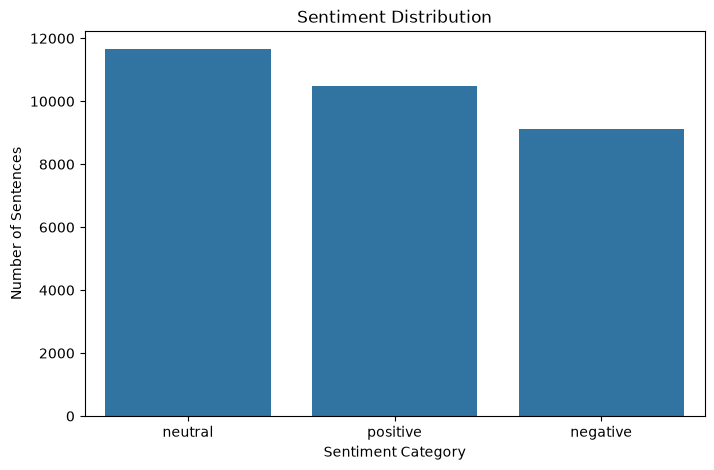

In [5]:

# Count each sentiment category
sentiment_counts = train_df['sentiment'].value_counts()

# Create a bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

# Add chart details
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Sentences")

plt.show()


In [6]:

# Display 10 random sentences
sample_data = train_df[['text', 'sentiment']].sample(10, random_state=42)

display(sample_data)


,text,sentiment
13132,@mashable I never did thank you for including ...,positive
7794,Happy Mothers Day!!,positive
28727,Welcome home! Glad you made it home safe!,positive
23700,@__Jasper_Hale__ *Laughs* that`s because I lik...,positive
19677,Getting ready for work... think I`m catching a...,neutral
17707,http://simoneserhan.tumblr.com new post,neutral
12927,*moment of silence* for the Budget i`m bout to...,negative
5346,well...gotta grab at least an hour and a half ...,negative
26405,I`ve been losing myself into too many Taiwanes...,negative
16420,Downtown was fun tonight The walk back to the...,neutral


In [12]:


import re
import pandas as pd

def clean_text(text):

    # Handle missing or non-string values
    if pd.isna(text):
        return ""

    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove usernames
    text = re.sub(r'@\w+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text



In [13]:

# Check for empty sentences after cleaning
empty_text = (train_df['cleaned_text'].str.len() == 0).sum()

print("Empty sentences after cleaning:", empty_text)

# Display the total number of sentences
print("Total sentences:", len(train_df))

# Check missing values in cleaned text
print("Missing cleaned text:", train_df['cleaned_text'].isnull().sum())


Empty sentences after cleaning: 0
Total sentences: 31193
Missing cleaned text: 0


In [9]:

# Remove rows with empty cleaned text
train_df = train_df[train_df['cleaned_text'].str.strip() != '']

# Reset the index
train_df = train_df.reset_index(drop=True)

# Verify the result
print("Dataset shape after cleaning:", train_df.shape)

print("Empty sentences remaining:",
      (train_df['cleaned_text'].str.len() == 0).sum())


Dataset shape after cleaning: (31193, 5)
Empty sentences remaining: 0


In [14]:

# Apply the same cleaning function to test data
test_df['cleaned_text'] = test_df['text'].apply(clean_text)

# Check the testing dataset
print("Testing Dataset Shape:", test_df.shape)

print("\nMissing Values:")
print(test_df.isnull().sum())

print("\nEmpty Sentences:",
      (test_df['cleaned_text'].str.strip() == '').sum())

# Display sample cleaned sentences
display(test_df[['text', 'cleaned_text', 'sentiment']].head())


Testing Dataset Shape: (5206, 5)

Missing Values:
id              0
text            1
label           0
sentiment       0
cleaned_text    0
dtype: int64

Empty Sentences: 7


,text,cleaned_text,sentiment
0,getting cds ready for tour,getting cds ready for tour,neutral
1,"MC, happy mother`s day to your mom ;).. love yah",mc happy mothers day to your mom love yah,positive
2,A year from now is graduation....i am pretty s...,a year from now is graduationi am pretty sure ...,negative
3,because you had chips and sale w/o me,because you had chips and sale wo me,neutral
4,Great for organising my work life balance,great for organising my work life balance,positive


In [15]:

# Remove empty cleaned sentences
test_df = test_df[test_df['cleaned_text'].str.strip() != '']

# Reset index
test_df = test_df.reset_index(drop=True)

# Verify the cleaned testing dataset
print("Testing Dataset Shape:", test_df.shape)

print("Empty Sentences Remaining:",
      (test_df['cleaned_text'].str.len() == 0).sum())

print("Missing Values:")
print(test_df.isnull().sum())


Testing Dataset Shape: (5199, 5)
Empty Sentences Remaining: 0
Missing Values:
id              0
text            0
label           0
sentiment       0
cleaned_text    0
dtype: int64


In [16]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=10000)

# Fit on training data and transform it
X_train = tfidf.fit_transform(train_df['cleaned_text'])

# Transform testing data using the same vectorizer
X_test = tfidf.transform(test_df['cleaned_text'])

# Extract sentiment labels
y_train = train_df['sentiment']
y_test = test_df['sentiment']

# Display shapes
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)


Training Features Shape: (31193, 10000)
Testing Features Shape: (5199, 10000)
Training Labels Shape: (31193,)
Testing Labels Shape: (5199,)


In [17]:

from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [18]:

# Predict sentiment using Logistic Regression
y_pred_lr = lr_model.predict(X_test)

# Display first 10 actual and predicted values
results = pd.DataFrame({
    'Actual Sentiment': y_test.iloc[:10].values,
    'Predicted Sentiment': y_pred_lr[:10]
})

display(results)


,Actual Sentiment,Predicted Sentiment
0,neutral,neutral
1,positive,positive
2,negative,neutral
3,neutral,negative
4,positive,positive
5,neutral,neutral
6,neutral,neutral
7,positive,neutral
8,negative,neutral
9,neutral,negative


In [19]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy * 100, "%")

Logistic Regression Accuracy: 67.378341988844 %


In [20]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred_lr))

Classification Report:
              precision    recall  f1-score   support

    negative       0.70      0.61      0.65      1545
     neutral       0.59      0.68      0.63      1928
    positive       0.76      0.72      0.74      1726

    accuracy                           0.67      5199
   macro avg       0.69      0.67      0.68      5199
weighted avg       0.68      0.67      0.68      5199



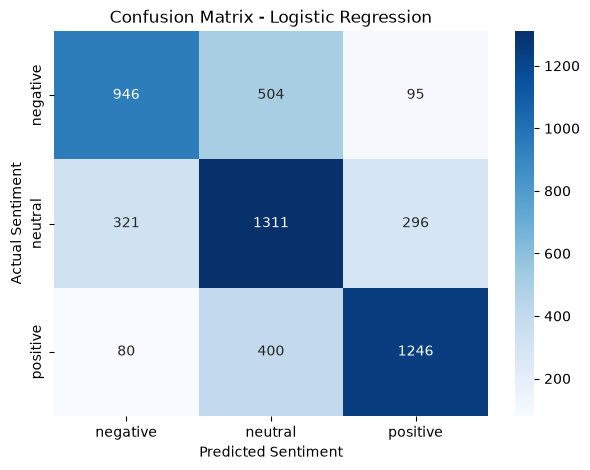

In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=lr_model.classes_,
    yticklabels=lr_model.classes_
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [22]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


In [23]:
# Predict sentiment using Naive Bayes
y_pred_nb = nb_model.predict(X_test)

# Calculate accuracy
from sklearn.metrics import accuracy_score

nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", nb_accuracy * 100, "%")

Naive Bayes Accuracy: 62.74283516060781 %


In [24]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train, y_train)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


In [25]:
# Predict sentiment using SVM
y_pred_svm = svm_model.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy * 100, "%")

SVM Accuracy: 66.07039815349106 %


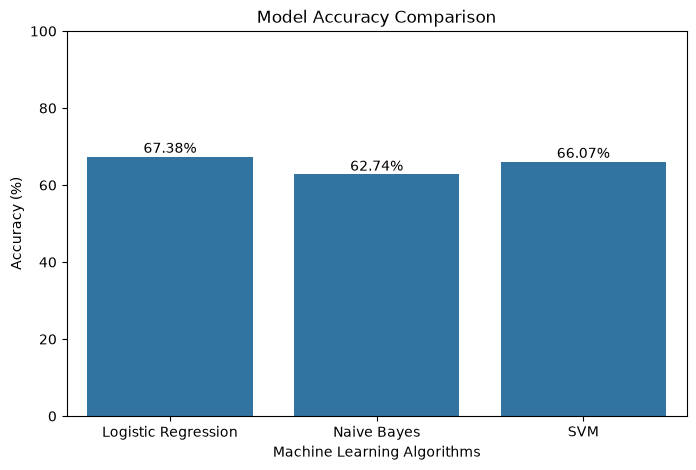

In [26]:
models = ['Logistic Regression', 'Naive Bayes', 'SVM']

accuracies = [
    accuracy * 100,
    nb_accuracy * 100,
    svm_accuracy * 100
]

plt.figure(figsize=(8, 5))

sns.barplot(x=models, y=accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.show()

In [27]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr))

print("\nNAIVE BAYES")
print(classification_report(y_test, y_pred_nb))

print("\nSVM")
print(classification_report(y_test, y_pred_svm))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    negative       0.70      0.61      0.65      1545
     neutral       0.59      0.68      0.63      1928
    positive       0.76      0.72      0.74      1726

    accuracy                           0.67      5199
   macro avg       0.69      0.67      0.68      5199
weighted avg       0.68      0.67      0.68      5199


NAIVE BAYES
              precision    recall  f1-score   support

    negative       0.71      0.49      0.58      1545
     neutral       0.54      0.69      0.60      1928
    positive       0.71      0.68      0.69      1726

    accuracy                           0.63      5199
   macro avg       0.65      0.62      0.63      5199
weighted avg       0.65      0.63      0.63      5199


SVM
              precision    recall  f1-score   support

    negative       0.67      0.63      0.65      1545
     neutral       0.60      0.62      0.61      1928
    positive       0.73      0.74    

In [28]:
from sklearn.linear_model import LogisticRegression

lr_tuned = LogisticRegression(
    C=2,
    max_iter=1000
)

lr_tuned.fit(X_train, y_train)

y_pred_tuned = lr_tuned.predict(X_test)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Tuned Logistic Regression Accuracy:",
      tuned_accuracy * 100, "%")

Tuned Logistic Regression Accuracy: 66.99365262550491 %


In [29]:
lr_tuned_05 = LogisticRegression(
    C=0.5,
    max_iter=1000
)

lr_tuned_05.fit(X_train, y_train)

y_pred_05 = lr_tuned_05.predict(X_test)

accuracy_05 = accuracy_score(y_test, y_pred_05)

print("Logistic Regression (C=0.5):",
      accuracy_05 * 100, "%")

Logistic Regression (C=0.5): 67.32063858434314 %


In [31]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 0.5, 1, 2, 5, 10]
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1:", grid_search.best_score_)

Best Parameters: {'C': 1}
Best Cross-Validation F1: 0.6639070201073611


In [32]:
# Get the best model
best_model = grid_search.best_estimator_

# Predict using the best model
y_pred_best = best_model.predict(X_test)

# Calculate test accuracy
best_accuracy = accuracy_score(y_test, y_pred_best)

print("Best Model Test Accuracy:",
      best_accuracy * 100, "%")

Best Model Test Accuracy: 67.378341988844 %


In [33]:
def predict_sentiment(sentence):
    cleaned = clean_text(sentence)
    transformed = tfidf.transform([cleaned])
    prediction = best_model.predict(transformed)

    return prediction[0]

print(predict_sentiment("I love this product"))
print(predict_sentiment("This is a terrible experience"))
print(predict_sentiment("The product is okay"))

positive
negative
neutral


In [34]:
while True:
    sentence = input("Enter a sentence (or type 'exit' to stop): ")

    if sentence.lower() == 'exit':
        print("Thank you for using Sentiment Analysis!")
        break

    result = predict_sentiment(sentence)

    print("Predicted Sentiment:", result)
    print("-----------------------------")

Enter a sentence (or type 'exit' to stop):  I hate this experience


Predicted Sentiment: negative
-----------------------------


Enter a sentence (or type 'exit' to stop):  The weather is normal.


Predicted Sentiment: neutral
-----------------------------


Enter a sentence (or type 'exit' to stop):  I am very happy today.


Predicted Sentiment: positive
-----------------------------


Enter a sentence (or type 'exit' to stop):  exit


Thank you for using Sentiment Analysis!


In [35]:
import joblib

joblib.dump(best_model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF Vectorizer saved successfully!")

Model and TF-IDF Vectorizer saved successfully!


In [36]:
import os

print("Saved Files:")

print(os.listdir())

Saved Files:
['.ipynb_checkpoints', 'Sentiment_Analysis.ipynb', 'sentiment_model.pkl', 'test_df.csv', 'tfidf_vectorizer.pkl', 'train_df.csv']


In [37]:
!pip freeze > requirements.txt

print("Requirements file created successfully!")

Requirements file created successfully!


In [38]:
requirements = """pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
jupyter
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("Project requirements updated successfully!")

Project requirements updated successfully!


In [39]:
readme = """# Sentiment Analysis Using Machine Learning

## Project Overview
This project uses Machine Learning and Natural Language Processing
to classify text into three sentiment categories:
- Positive
- Negative
- Neutral

## Objective
To build a sentiment classification system that understands
textual input and predicts the sentiment expressed by the user.

## Dataset
- Training samples: 31,193
- Testing samples: 5,199
- Classes: Positive, Negative, Neutral

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- NLTK
- Matplotlib
- Seaborn
- TF-IDF

## Data Preprocessing
- Converted text to lowercase
- Removed URLs and usernames
- Removed special characters and punctuation
- Removed empty sentences

## Machine Learning Algorithms
1. Logistic Regression
2. Multinomial Naive Bayes
3. Linear Support Vector Machine (SVM)

## Model Performance

| Algorithm | Accuracy |
|---|---:|
| Logistic Regression | 67.38% |
| Multinomial Naive Bayes | 62.74% |
| Linear SVM | 66.07% |

## Hyperparameter Tuning
GridSearchCV with 3-fold cross-validation was used.
Best parameter: C = 1

## Final Model
Logistic Regression

Test Accuracy: 67.38%

## Saved Model Files
- sentiment_model.pkl
- tfidf_vectorizer.pkl

## How to Run

1. Clone or download this repository.
2. Install the required libraries:

   pip install -r requirements.txt

3. Open Sentiment_Analysis.ipynb in Jupyter Notebook.
4. Run the notebook cells sequentially.

## Future Improvements
- Improve model accuracy
- Experiment with advanced NLP techniques
- Build a web interface using Flask
- Support multiple languages

## Author
Divya
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [40]:
import os

for file in os.listdir():
    if file != ".ipynb_checkpoints":
        print(file)

README.md
requirements.txt
Sentiment_Analysis.ipynb
sentiment_model.pkl
test_df.csv
tfidf_vectorizer.pkl
train_df.csv


## Dataset Attribution

Dataset: Multiclass Sentiment Analysis Dataset

Source:
https://huggingface.co/datasets/Sp1786/multiclass-sentiment-analysis-dataset

Author: Sp1786

License: Apache License 2.0
https://www.apache.org/licenses/LICENSE-2.0